<a href="https://colab.research.google.com/github/Rahma000882/AI-Project/blob/main/DBSCAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **DBSCAN**

**DBSCAN (Density-Based Spatial Clustering of Applications with Noise) is a popular clustering algorithm used in machine learning and data mining.**

**It's particularly useful for identifying clusters of varying shapes and sizes within a dataset, especially in scenarios where clusters may have varying densities or where there might be noise (outliers).**

**Centrally, all clustering methods use the same approach i.e. first we calculate similarities and then we use it to cluster the data points into groups or batches.**

### **Why do we need a Density-Based clustering algorithm like DBSCAN when we already have K-means clustering?**

- **Handling Noise and Outliers**:
    - **DBSCAN** is robust to noise and outliers because it identifies points that are not part of any cluster as noise points.
    - **K-Means**, on the other hand, assigns every point to a cluster, potentially leading to suboptimal clustering results in the presence of outliers.

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans, DBSCAN
from sklearn.datasets import make_moons
import warnings
warnings.filterwarnings('ignore')

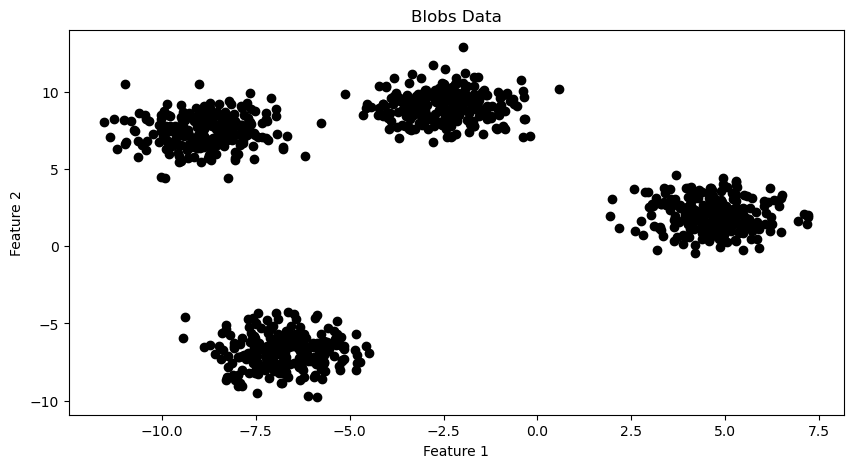

In [ ]:
# Generate synthetic data
X, _ = make_blobs(n_samples=1000, centers=4, random_state=42)

plt.figure(figsize=(10, 5))

plt.scatter(X[:, 0], X[:, 1], c='black')
plt.title('Blobs Data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')

plt.show()

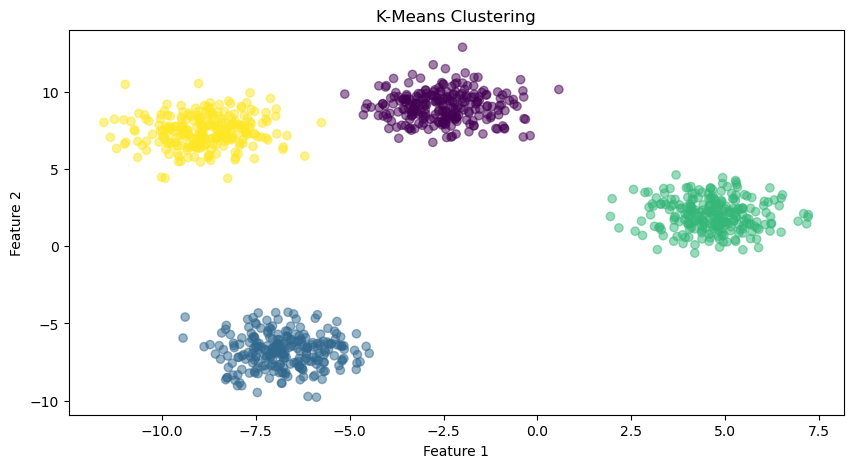

In [ ]:
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans_labels = kmeans.fit_predict(X)

plt.figure(figsize=(10, 5))

plt.scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap='viridis', alpha=0.5)
plt.title('K-Means Clustering')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')

plt.show()

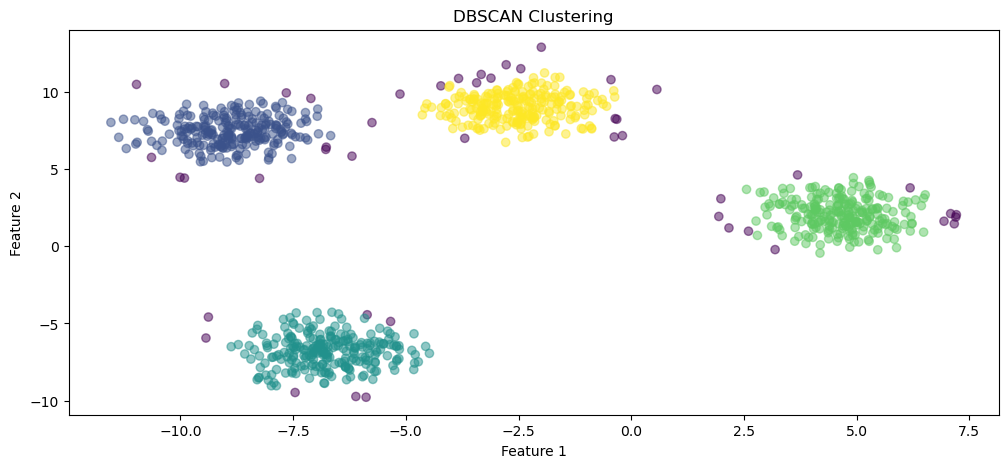

In [ ]:
dbscan = DBSCAN(eps=0.6, min_samples=6)
dbscan_labels = dbscan.fit_predict(X)

plt.figure(figsize=(12, 5))

plt.scatter(X[:, 0], X[:, 1], c=dbscan_labels, cmap='viridis', alpha=0.5)
plt.title('DBSCAN Clustering')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')

plt.show()

- **Ability to Identify Arbitrary Shapes**
    - DBSCAN can identify clusters of arbitrary shapes, whereas K-Means assumes clusters to be spherical and isotropic.
    - This makes DBSCAN more suitable for datasets with clusters of irregular shapes or varying densities.

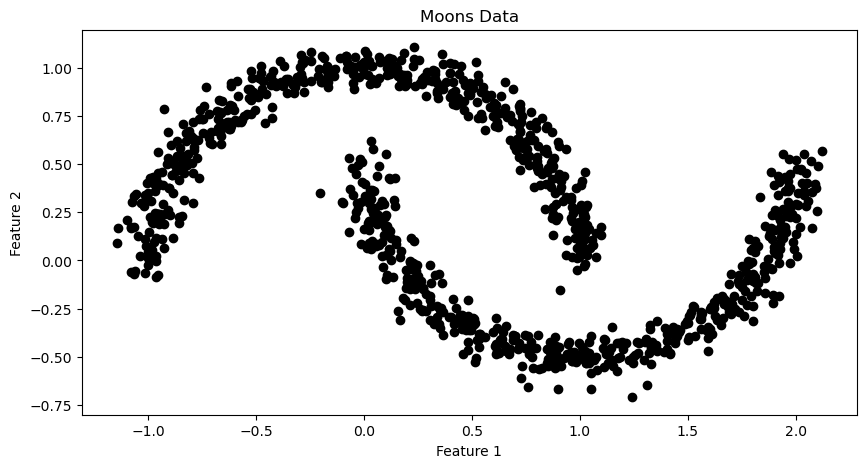

In [ ]:
X, _ = make_moons(n_samples=1000, noise=0.06)

plt.figure(figsize=(10, 5))

plt.scatter(X[:, 0], X[:, 1], c='black')
plt.title('Moons Data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')

plt.show()

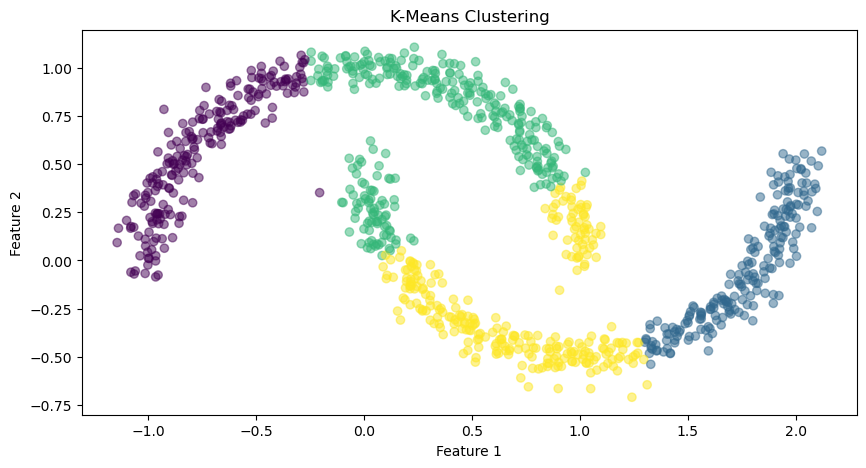

In [ ]:
kmeans = KMeans(n_clusters=4)
kmeans_labels = kmeans.fit_predict(X)

plt.figure(figsize=(10, 5))

plt.scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap='viridis', alpha=0.5)
plt.title('K-Means Clustering')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')

plt.show()

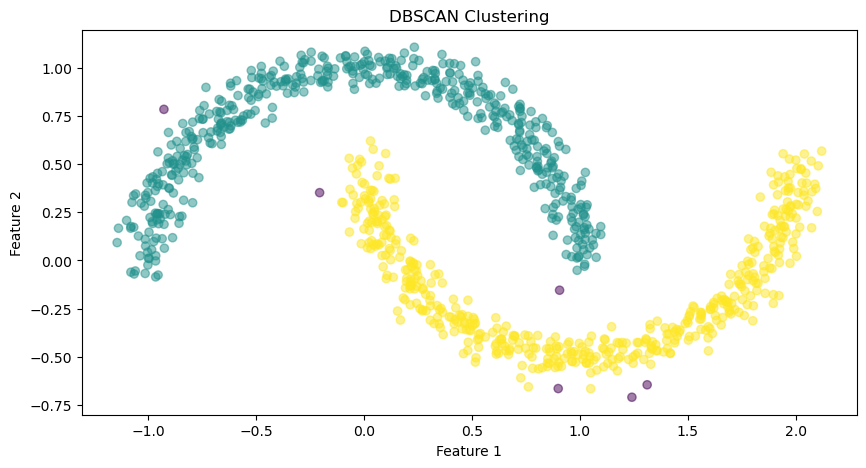

In [ ]:
dbscan = DBSCAN(eps=0.1, min_samples=5)
dbscan_labels = dbscan.fit_predict(X)

plt.figure(figsize=(10, 5))

plt.scatter(X[:, 0], X[:, 1], c=dbscan_labels, cmap='viridis', alpha=0.5)
plt.title('DBSCAN Clustering')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')

plt.show()

- **Automatic Determination of Number of Clusters**
    - DBSCAN automatically determines the number of clusters based on the data and the parameters ('eps' and 'min_samples').
    - In contrast, K-Means requires the user to specify the number of clusters beforehand, which may not always be known or may vary across datasets.

- **Less Sensitivity to Initialization:**
    - K-Means clustering is sensitive to the initial choice of cluster centroids, which can lead to different final clustering results depending on the initialization.
    - DBSCAN, on the other hand, is less sensitive to initialization, as it defines clusters based on density rather than centroids.

### **DBSCAN Process**
![DBSCAN_tutorial.gif](attachment:DBSCAN_tutorial.gif)


1. **Initialization:**
- Choose two parameters:
    - **ε (epsilon):** The radius of the neighborhood around a point.
    - **MinPts:** The minimum number of points within ε required to form a dense region.

2. **Core Points Identification:**
- For each point in the dataset:
    - Count the number of points within its ε neighborhood.
    - If the number of points within the neighborhood is greater than or equal to MinPts, mark the point as a core point.

3. **Expansion of Core Points:**
    - For each core point:
        - Create a new cluster or expand an existing one.
        - Recursively find all points that are directly reachable from the core point within ε.
        - Add these points to the cluster.
        - If a point is a core point itself, repeat the process for its ε neighborhood.

    ![dbscan.png](attachment:dbscan.png)


4. **Border Points Assignment:**
    - For each border point (a point that is not a core point but is within the ε neighborhood of a core point):
        - Assign the border point to the cluster of its corresponding core point.

5. **Noise Points Identification:**
    - Any point that is not a core point or a border point is considered a noise point and is not assigned to any cluster.

6. **Cluster Formation:**
    - Repeat the expansion process until all points have been visited and assigned to clusters or labeled as noise.

### **DBSCAN Parameter Selection**

**To see changes in parameters, visit this [site](https://www.naftaliharris.com/blog/visualizing-dbscan-clustering/)**

1. **MinPts:**
    - MinPts specifies the minimum number of points required to form a dense region.
    - It's generally recommended that the minPts parameter should not be less than 3, this is because, DBSCAN requires at least three points (including the core point itself) to be within the *ε-neighborhood* of each core point.
    - If the dataset is noisy or contains outliers, a larger value of minPts may be necessary to ensure robust clustering.
2. **eps:**
    - When choosing the eps parameter in DBSCAN, it's essential to strike a balance between including enough points in each cluster and avoiding over-clustering or under-clustering.
    - If a small eps is chosen, it may result in many points not being assigned to any cluster, leading to under-clustering.
    - Conversely, if eps is too large, many points may be assigned to the same cluster, potentially leading to over-clustering.
    
    - **You can Identify the Elbow Point**

### **Advantages:**
- **DBSCAN is capable of identifying clusters of arbitrary shape and size, making it suitable for datasets with complex structures.**

- **DBSCAN is robust to noise and outliers in the dataset. It achieves this by defining clusters as regions of high density separated by regions of low density, effectively ignoring noise points.**

- **DBSCAN automatically determines the density of clusters based on the *eps* and *minPts* parameters. It does not require specifying the number of clusters beforehand, which can be challenging in many real-world datasets.**

### **Disadvantages:**
- **DBSCAN's performance is highly sensitive to the choice of parameters, particularly *eps* and *minPts*. Selecting optimal values for these parameters can be challenging and may require domain knowledge or experimentation.**

- **Not deterministic as border points that is accessed by several clusters can be either a part of any cluster based on the order the data processed.**

- **Fails at very high dimensional data due to curse of dimensionality.**
- **DBSCAN algorithm is somewhat more difficult to tune contrasted to KMeans.**
-----------------------------
---------------------------------